# 03 · Sequential per-tree detection — contribution 1

Every published acoustic method asks: *does this 20-second clip sound
infested?* That is single-recording, cross-tree classification. It suits a
technician walking a plantation with a probe.

A sensor bolted to one tree makes a different and easier question available:

> **has this tree changed from its own baseline?**

Three ideas:

1. **Separate tree identity from the infestation shift.** Where a tree sits in
   feature space varies enormously between trees — that is what leaked in
   notebook 02. The *direction* feeding activity moves a tree is shared,
   because the biology is the same. Centre every training tree on its own
   clean mean to delete identity, then learn only the direction.

2. **Calibrate per tree, without labels.** A deployed device models its own
   tree's healthy state during a learning period after installation.

3. **Accumulate evidence instead of judging single clips.** A young
   infestation is a few larvae in a large trunk, so most recordings contain
   nothing. Sequential testing integrates them; detectable effect size falls
   roughly as 1/√N. That is the formal reason it detects earlier.

The 2026 review names the matching gap: standardised, time-resolved monitoring.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent          # the nakheel-guard folder
for sub in ("src", "scripts"):
    sys.path.insert(0, str(ROOT / sub))

# These imports are wrapped because the most common way they fail on Anaconda
# produces an error that never mentions the real cause. Installing an audio
# library with pip can upgrade NumPy past 2.0, and Anaconda's pre-compiled
# matplotlib / scipy / pandas were built against NumPy 1.x -- so the failure
# surfaces as "initialization failed" deep inside matplotlib's import chain,
# with no hint that NumPy is responsible.
try:
    import numpy as np, pandas as pd, matplotlib.pyplot as plt
except ImportError as _exc:
    _numpy_version = "unknown"
    try:
        import numpy as _np_probe
        _numpy_version = _np_probe.__version__
    except Exception:
        pass
    raise ImportError(f"""Core imports failed. NumPy version: {_numpy_version}

This is almost always a mixed environment: some packages were built for
NumPy 1.x and others require NumPy 2.x, so no single NumPy version satisfies
everything. Typical symptoms are "module compiled using NumPy 1.x cannot be
run in NumPy 2" or "module 'numpy' has no attribute 'long'".

Pinning NumPy does NOT fix this -- in a genuinely mixed environment each pin
only moves the failure to a different package. Build a clean environment:

    conda create -n nakheel python=3.11 -y
    conda activate nakheel
    pip install -r requirements.txt
    pip install jupyterlab ipykernel
    python -m ipykernel install --user --name nakheel --display-name "Python (nakheel)"

then start Jupyter from that prompt and choose
Kernel -> Change Kernel -> Python (nakheel).

If a package is merely missing rather than mismatched, install it into THIS
kernel with:

    import sys
    !"{sys.executable}" -m pip install --upgrade-strategy only-if-needed <package>

Original error: {_exc}
""") from _exc

get_ipython().run_line_magic("matplotlib", "inline")
pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 40)

In [2]:
# ---------------------------------------------------------------- packages
# Check the packages this project needs are importable *in the Python that is
# running this notebook*. On Anaconda, `pip` on the command line often points
# at a different environment than Jupyter uses, which is a common and
# confusing source of "but I installed it" failures.
_missing = []
for _mod, _pkg in [("numpy", "numpy"), ("pandas", "pandas"),
                   ("sklearn", "scikit-learn"), ("scipy", "scipy"),
                   ("librosa", "librosa"), ("soundfile", "soundfile"),
                   ("joblib", "joblib"), ("matplotlib", "matplotlib"),
                   ("openpyxl", "openpyxl")]:
    try:
        __import__(_mod)
    except ImportError:
        _missing.append(_pkg)

if _missing:
    raise ImportError(f"""Missing packages: {', '.join(_missing)}

Install them into THIS kernel by running the following in a new cell,
then restart the kernel (Kernel -> Restart):

    import sys
    !"{sys.executable}" -m pip install --upgrade-strategy only-if-needed {' '.join(_missing)}

The --upgrade-strategy flag matters: without it pip may upgrade NumPy to
satisfy the new package, which can break other packages compiled against a
different NumPy generation. If that happens, see the README -- the fix is a
clean environment, not a NumPy pin.
""")

print("packages: OK")

# ---------------------------------------------------------------- dataset
# "mock"      - structurally faithful stand-in, synthetic audio. For testing.
# "treevibes" - the real download. Put it in data/treevibes/.
WHICH = "treevibes"

DATASETS = {
    "mock":      ROOT / "data" / "mock_treevibes",
    "treevibes": ROOT / "data" / "treevibes",
}
DATASET = DATASETS[WHICH]
TAG = "mock" if WHICH == "mock" else "treevibes"

# The Kaggle distribution splits into field/ and lab/. Only the field
# recordings describe deployed sensors on real trees -- the lab set is
# controlled-condition material that would both swamp the field data (roughly
# 53,000 clips against 4,000) and mix two very different acoustic regimes
# under one label. The published analyses use the field recordings, so that
# is what this project evaluates on.
if WHICH == "treevibes" and (DATASET / "field").is_dir():
    DATASET = DATASET / "field"
    print("using the field recordings only (lab/ excluded)")

if not DATASET.exists():
    if WHICH == "mock":
        # Imported and called directly rather than run as a subprocess, so a
        # failure arrives as an ordinary traceback naming its cause instead
        # of an opaque "non-zero exit status 1".
        import make_mock_treevibes
        print("building the mock dataset (a few minutes)...")
        make_mock_treevibes.generate(out=DATASET, folders=10, days=110,
                                     per_day=2, seconds=3.0)
    else:
        raise FileNotFoundError(f"""{DATASET} not found.

Download TreeVibes from
    https://www.kaggle.com/datasets/potamitis/treevibes
and extract it into
    {DATASET}
""")
print(f"dataset: {DATASET}  (tag '{TAG}')")

packages: OK
using the field recordings only (lab/ excluded)
dataset: C:\Users\DELL\Downloads\nakheel-final\nakheel-final\data\treevibes\field  (tag 'treevibes')


In [3]:
import extract as E

cached = E.load_cache(TAG)
if cached is None:
    raise FileNotFoundError(f"No cached features for '{TAG}'. Run notebook 01.")
X, y, groups, clip_ids, names = cached
trees = np.unique(groups)
print(f"{X.shape[0]} windows, {len(trees)} trees")

38675 windows, 36 trees


## 1. Hold out whole trees

Everything below is measured on trees never used to learn the shift direction.

In [4]:
rng = np.random.default_rng(0)
tree_label = {t: int(y[groups == t][0]) for t in trees}
clean_trees    = [t for t in trees if tree_label[t] == 0]
infested_trees = [t for t in trees if tree_label[t] == 1]

# Hold out from both classes, or the score pools cannot be built.
n_hold = max(1, len(trees) // 5)
test_trees = (list(rng.choice(clean_trees, min(n_hold, len(clean_trees)), replace=False))
              + list(rng.choice(infested_trees, min(n_hold, len(infested_trees)), replace=False)))
train_mask = ~np.isin(groups, test_trees)
print("held out:", test_trees)

held out: [np.str_('field/train/folder_9/folder_9'), np.str_('field/train/folder_10'), np.str_('field/train/folder_7'), np.str_('field/train/folder_35'), np.str_('field/train/folder_8'), np.str_('field/train/folder_25'), np.str_('field/train/folder_24'), np.str_('field/train/folder_5'), np.str_('field/train/folder_18'), np.str_('field/train/folder_6'), np.str_('field/train/folder_14'), np.str_('field/train/folder_16'), np.str_('field/train/folder_15'), np.str_('field/train/folder_22')]


## 2. Learn the shift direction with tree identity removed

In [5]:
from sequential import fit_shift_direction, fit_shift_direction_pooled

try:
    w, scaler, info = fit_shift_direction(X[train_mask], y[train_mask],
                                          groups[train_mask])
    WITHIN_TREE = True
except ValueError as err:
    print("within-tree contrast unavailable:", str(err).splitlines()[0])
    print("falling back to the pooled estimate — this IS a limitation,\n"
          "and it must be stated wherever the result is reported.\n")
    w, scaler, info = fit_shift_direction_pooled(X[train_mask], y[train_mask],
                                                 groups[train_mask])
    WITHIN_TREE = False

for k, v in info.items():
    if k != "trees_used":
        print(f"  {k}: {v}")

within-tree contrast unavailable: After centring, only one class remains. This happens when every tree is wholly clean or wholly infested, so no within-tree contrast exists. Use fit_shift_direction_pooled() instead and state the limitation.
falling back to the pooled estimate — this IS a limitation,
and it must be stated wherever the result is reported.



  n_trees_used: 22
  within_tree_contrast: False
  effect_size_cohens_d: 3.3530317735611628


## 3. Does the direction survive on an unseen tree?

**Run this before anything else.** A direction can separate the training
trees perfectly and still be useless — or actively harmful — on a new tree.

When every tree is wholly clean or wholly infested, *"which tree"* and
*"which class"* are the same variable, so the direction is free to encode
tree idiosyncrasies that point somewhere arbitrary on a tree it has not seen.

The dangerous outcome is **inversion**: held-out `d` comes out negative. A
sequential detector built on an inverted direction accumulates evidence
*downward*, so it becomes **less** likely to alarm the worse the infestation
gets — failing exactly when it matters, while looking well-behaved on every
training diagnostic.

In [6]:
from experiments import check_direction_transfer

transfer = check_direction_transfer(X, y, groups, test_trees, w, scaler)

  direction transfer: train d=+3.35  held-out d=+0.33  ->  WEAK


### How to read the verdict

| verdict | meaning | what to report |
|---|---|---|
| `transfers` | the direction generalises | the sequential results below are meaningful |
| `weak` | it generalises partly | report the retained fraction honestly |
| `collapses` | it carries nothing general | the method needs within-tree data |
| `inverts` | it points the **wrong way** | **the strongest evidence that the model learned tree identity, not infestation** |

An `inverts` or `collapses` verdict is **not a failed project**. It is a
measured, reproducible finding that explains why published near-100%
accuracies on this dataset do not describe field performance, and it tells
the field precisely what data it needs: **trees recorded in both states.**

Everything below still runs, so you can see the consequence. If the verdict
is `inverts`, present the detection curves as *the consequence of an inverted
direction*, not as a performance claim.

## 4. Per-tree baselines, then score held-out recordings

Half of each held-out tree's **clean** recordings fit its baseline; the rest
are scored. This mirrors deployment: the device is installed on a tree that is
healthy at the time.

In [7]:
from experiments import build_score_pools

clean_scores, infested_scores, pinfo = build_score_pools(
    X, y, groups, test_trees, w, scaler, seed=1)

for k, v in pinfo.items():
    print(f"  {k}: {v}")

d = ((infested_scores.mean() - clean_scores.mean())
     / np.sqrt((clean_scores.var() + infested_scores.var()) / 2))
print(f"\nheld-out separation, Cohen's d = {d:.2f}")

  trees_within_tree_contrast: []
  trees_cross_tree_fallback: ['field/train/folder_9/folder_9', 'field/train/folder_10', 'field/train/folder_7', 'field/train/folder_35', 'field/train/folder_8', 'field/train/folder_25', 'field/train/folder_24']
  trees_skipped_no_baseline: ['field/train/folder_5', 'field/train/folder_18', 'field/train/folder_6', 'field/train/folder_14', 'field/train/folder_16', 'field/train/folder_15', 'field/train/folder_22']
  contrast: cross-tree fallback

held-out separation, Cohen's d = 0.61


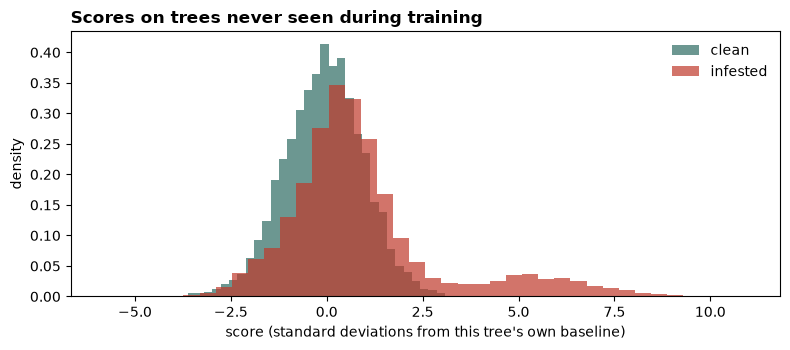

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(clean_scores, bins=40, alpha=0.7, label="clean", color="#2E6B63", density=True)
ax.hist(infested_scores, bins=40, alpha=0.7, label="infested", color="#C0392B", density=True)
ax.set_xlabel("score (standard deviations from this tree's own baseline)")
ax.set_ylabel("density"); ax.legend(frameon=False)
ax.set_title("Scores on trees never seen during training", loc="left", fontweight="bold")
plt.tight_layout()

Heavy overlap is the honest situation: a **single** recording cannot separate
the classes. The method's point is that it does not need to.

## 5. One monitoring stream

Infestation is modelled as a rising **prevalence** p(t): the probability that
a given recording contains feeding. Observations are drawn from the tree's
*real* clean recordings with probability 1−p(t) and from *real* infested
recordings with probability p(t).

Notebook 04 replaces this simulated ordering with the dataset's real
timestamps.

In [9]:
from simulate import make_stream, make_healthy_stream
from sequential import cusum, calibrate_threshold

N_OBS, ONSET, RAMP, PREVALENCE = 180, 60, 45, 0.35
rng = np.random.default_rng(7)

healthy = [make_healthy_stream(clean_scores, N_OBS, rng) for _ in range(200)]
h = calibrate_threshold(healthy, k=0.5, target_false_alarms_per_year=0.5,
                        obs_per_year=N_OBS)
print(f"alarm threshold h = {h:.2f}  "
      f"(0.5 false alarms per tree per {N_OBS} observations)")

stream, p_curve = make_stream(clean_scores, infested_scores, N_OBS, ONSET,
                              RAMP, PREVALENCE, rng=rng)
alarm, S = cusum(stream, k=0.5, h=h)
print(f"onset {ONSET}, alarm {alarm}, "
      f"delay {None if alarm is None else alarm - ONSET}")

alarm threshold h = 3.75  (0.5 false alarms per tree per 180 observations)
onset 60, alarm 66, delay 6


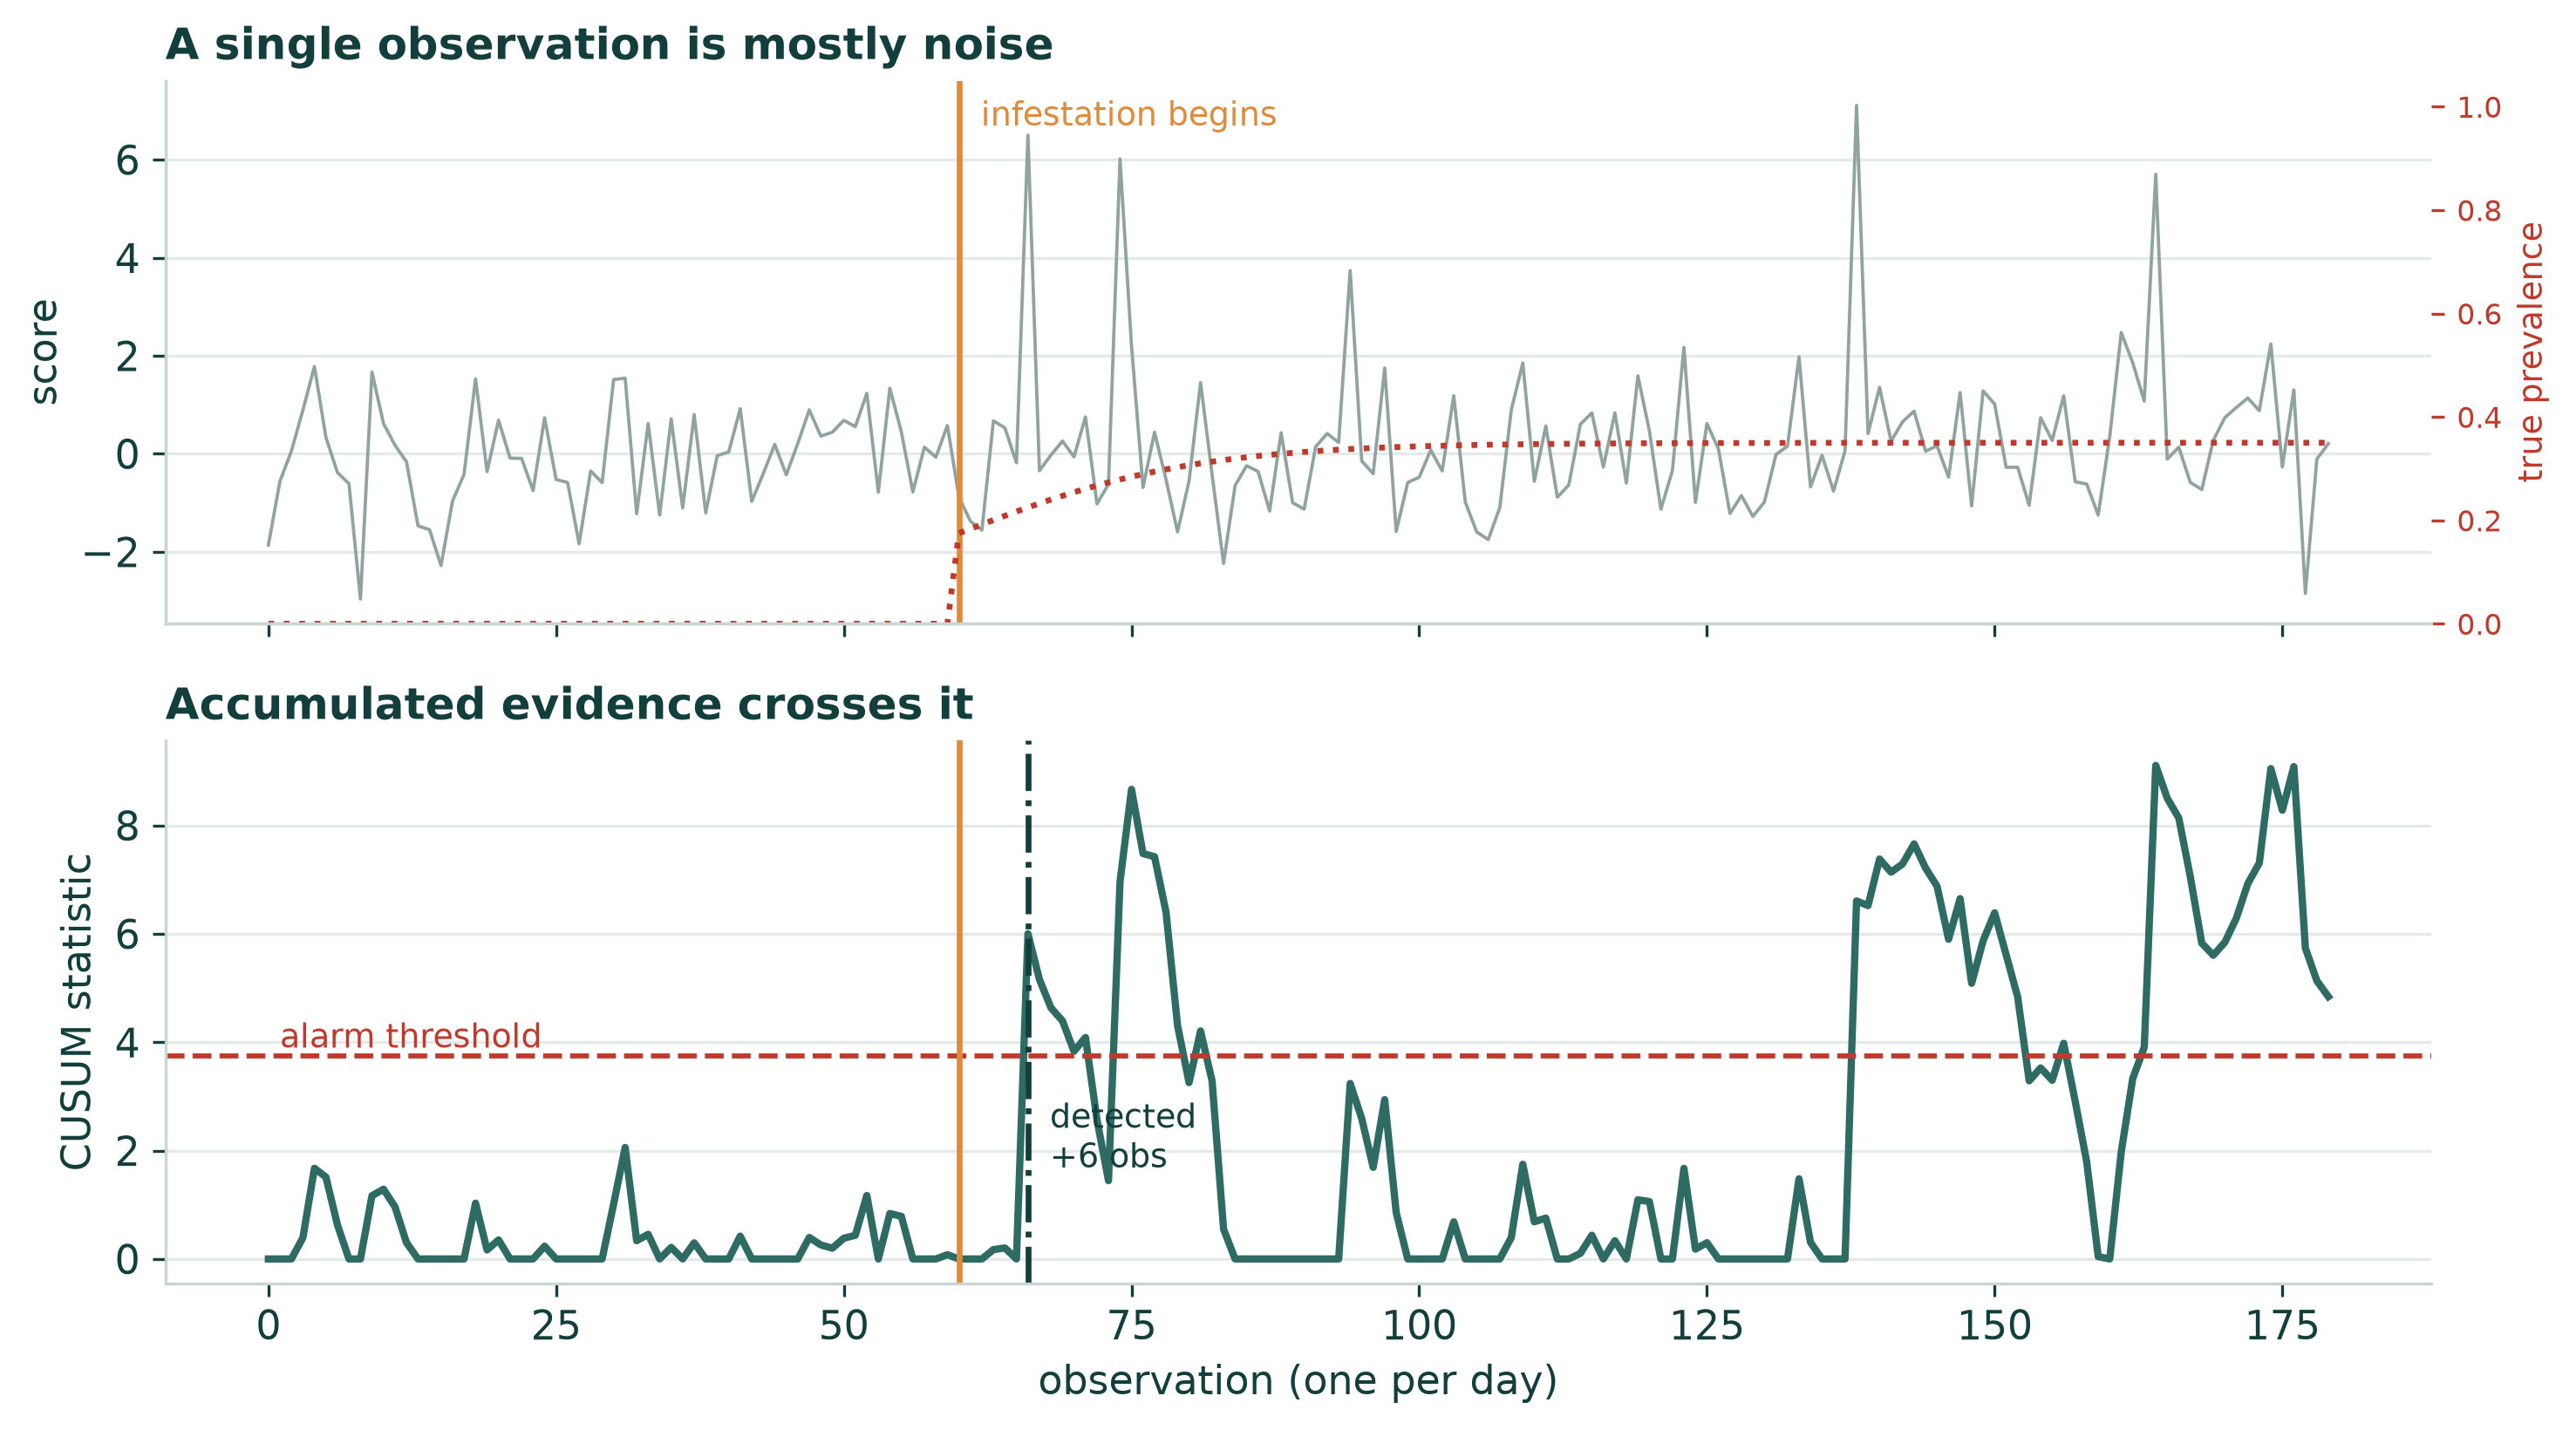

In [10]:
import plots as P
from IPython.display import Image, display
display(Image(str(P.fig_stream_example(stream, p_curve, S, h, ONSET, alarm)), width=840))

## 6. The headline experiment

Compare against the published framing — per-clip classification applied to the
same stream — with **both detectors calibrated to the same false-alarm
budget**. Without that step the comparison is meaningless: any detector looks
faster if allowed to cry wolf more often.

In [11]:
from experiments import run_comparison, summarise

res = run_comparison(clean_scores, infested_scores,
                     n_obs=N_OBS, onset=ONSET, ramp=RAMP,
                     n_trials=300, false_alarms_per_year=0.5, seed=1)
print(summarise(res))

Calibration (both detectors held to the same budget)
  budget                      : 0.50 false alarms per tree per 180 observations
  observed, sequential CUSUM  : 0.463
  observed, per-clip rule     : 0.510
  CUSUM threshold h           : 3.75
  per-clip threshold          : 1.46 (2 consecutive)

Detection (delay in observations after onset)
  prevalence | CUSUM rate   delay |  clip rate   delay
  ----------------------------------------------------
        0.05 |       0.57      52 |       0.37      51
        0.10 |       0.70      38 |       0.44      51
        0.20 |       0.80      29 |       0.52      52
        0.35 |       0.85      19 |       0.63      40
        0.50 |       0.81      14 |       0.70      36
        0.75 |       0.83       9 |       0.76      31
        1.00 |       0.84       7 |       0.80      21


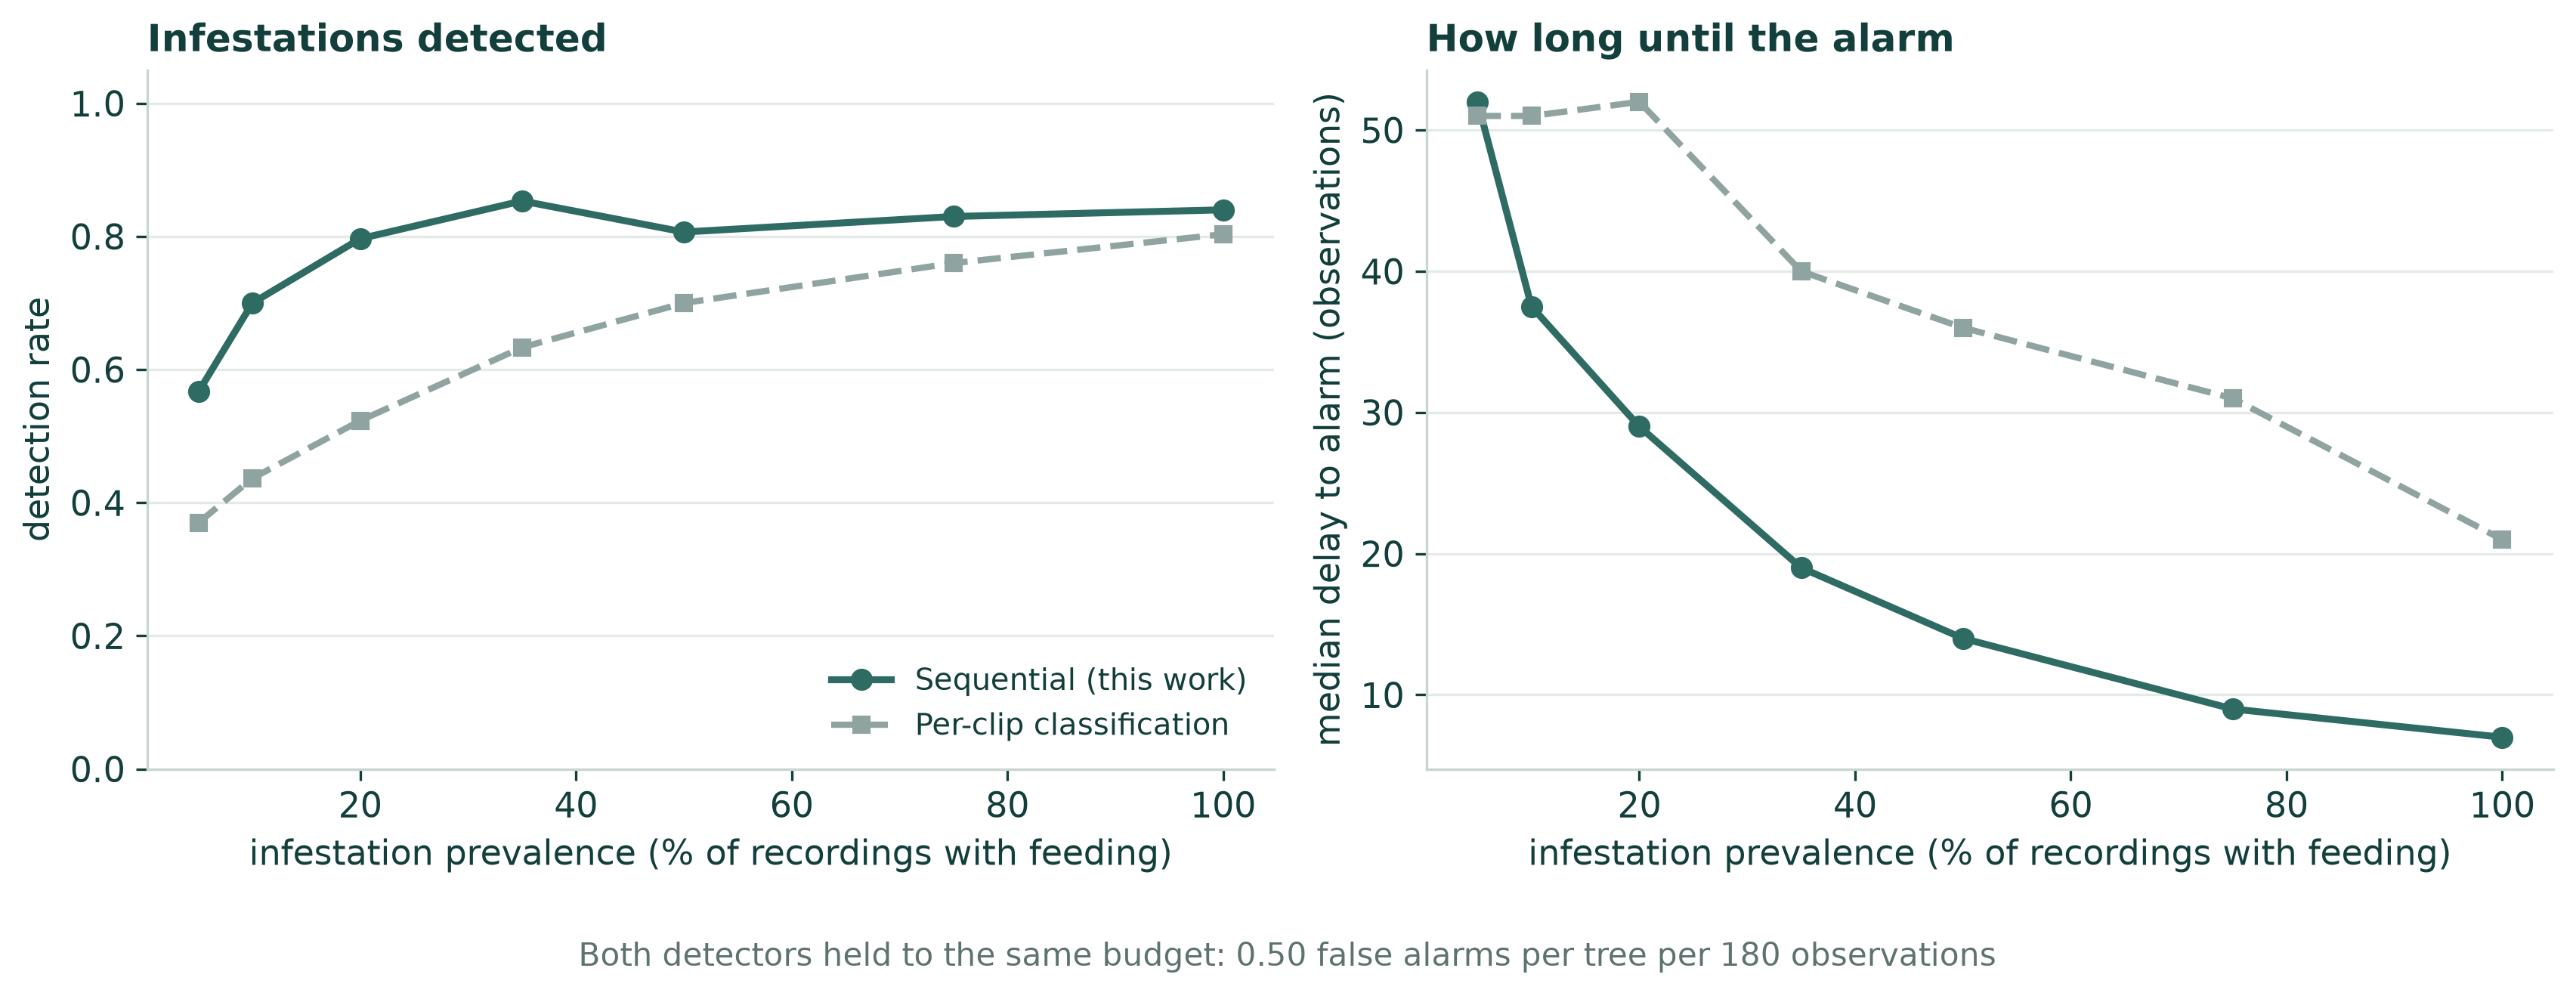

,final_prevalence,cusum_detection_rate,cusum_median_delay,cusum_mean_delay,perclip_detection_rate,perclip_median_delay,perclip_mean_delay
0,0.05,0.567,52.0,54.212,0.370,51.0,53.387
1,0.10,0.700,37.5,43.019,0.437,51.0,53.870
2,0.20,0.797,29.0,36.280,0.523,52.0,53.439
3,0.35,0.853,19.0,25.301,0.633,40.0,46.068
4,0.50,0.807,14.0,20.128,0.700,36.0,44.005
5,0.75,0.830,9.0,12.892,0.760,31.0,35.645
6,1.00,0.840,7.0,9.960,0.803,21.0,26.041


In [12]:
display(Image(str(P.fig_detection_delay(res)), width=880))
res.round(3)

In [13]:
res.to_csv(P.RESULTS_DIR / "sequential_results.csv", index=False)
import json
(P.RESULTS_DIR / "sequential_attrs.json").write_text(
    json.dumps({**{k: (float(v) if isinstance(v, (int, float)) else v)
                   for k, v in res.attrs.items()},
                "within_tree_contrast": bool(WITHIN_TREE),
                "direction_transfer": transfer}, indent=2))
print("saved results/sequential_results.csv")

saved results/sequential_results.csv


Continue to **04 · Temperature and season**, which replaces the simulated
ordering above with the dataset's real timestamps and addresses a second gap
the review names.